In [23]:
from itertools import islice
import time

import numpy as np
import pandas as pd

## 1. Wczytanie danych

In [24]:
clicks = pd.concat(
    chunk.loc[chunk["event"] == "click", ["user", "item", "timestamp"]]
    for chunk in pd.read_csv("data/interactions.csv", chunksize=2_000_000)
)

clicks["timestamp"] = pd.to_datetime(clicks["timestamp"], unit="s")

print("liczba kliknięć: ", len(clicks))
print("liczba użytkowników: ", clicks["user"].nunique())
print("liczba ofert: ", clicks["item"].nunique())
print("okres od: ", clicks["timestamp"].min(), " do: ", clicks["timestamp"].max())
clicks.head()

liczba kliknięć:  17774107
liczba użytkowników:  1479598
liczba ofert:  155706
okres od:  1970-01-01 00:02:38  do:  2020-02-15 22:09:59


,user,item,timestamp
0,27901,56865,2020-02-12
1,124480,115662,2020-02-12
2,159509,5150,2020-02-12
3,188861,109981,2020-02-12
4,207348,88746,2020-02-12


In [7]:
#clicks.to_parquet("data/clicks.parquet", index=False)
# clicks = pd.read_parquet("data/clicks.parquet")

## 2. Losowe 10% użytkowników

In [25]:
users = clicks["user"].drop_duplicates().sample(frac=0.1, random_state=42)
sample = clicks[clicks["user"].isin(users)]

print(f"{len(users)} użytkowników, {len(sample)} kliknięć")

147960 użytkowników, 1783094 kliknięć


## 3. Temporal split

In [26]:
t_split = sample["timestamp"].quantile(0.8)

train = sample[sample["timestamp"] < t_split]
test = sample[sample["timestamp"] >= t_split]

print("t_split:", t_split)
print(f"train: {len(train)}, test: {len(test)}")

t_split: 2020-02-15 03:03:06
train: 1426470, test: 356624


## 4. Katalog: 10% najpopularniejszych ofert

In [27]:
pop = train["item"].value_counts()
catalog = pop.head(int(len(pop) * 0.1)).index

train = train[train["item"].isin(catalog)]
test = test[test["item"].isin(catalog)]

print(f"liczba ofert w katalogu: {len(catalog)}")
print(f"zostało w train: {pop[catalog].sum() / pop.sum():.1%} kliknięć")

print(f"train: {train['user'].nunique()} userów, {train['item'].nunique()} ofert, {len(train)} interakcji")
print(f"test: {test['user'].nunique()} userów, {test['item'].nunique()} ofert, {len(test)} interakcji")

liczba ofert w katalogu: 11377
zostało w train: 47.2% kliknięć
train: 97199 userów, 11377 ofert, 673057 interakcji
test: 34321 userów, 11134 ofert, 132844 interakcji


In [28]:
# Zostawiamy Ttylko użytkowników, którzy po filtrze katalogu zostali w zbiorze testowym i treningowym. 

train_items = train.groupby("user")["item"].agg(set)
test_items = test.groupby("user")["item"].agg(set)

eval_users = train_items.index.intersection(test_items.index)
test_items = test_items[eval_users]

print(f"liczba użytkowników: {len(eval_users)}")
print(f"średnio ofert w teście: {test_items.map(len).mean():.2f}")

liczba użytkowników: 20507
średnio ofert w teście: 3.60


In [29]:
overlap = [len(test_items[u] & train_items[u]) / len(test_items[u]) for u in eval_users]
print(f"oferty z testu widziane już w train: {np.mean(overlap):.1%}")

oferty z testu widziane już w train: 20.6%


## Analiza danych

Trzy proste wykresy, żeby zorientować się w danych: aktywność użytkowników, rozkład kliknięć w czasie i koncentracja kliknięć na najpopularniejszych ofertach.

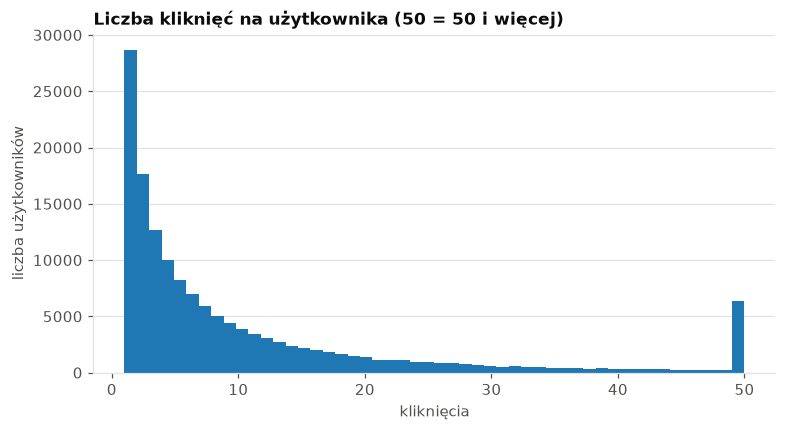

mediana kliknięć na użytkownika: 5.0


In [30]:
import matplotlib.pyplot as plt

user_clicks = sample.groupby('user').size()

plt.figure(figsize=(8, 4))
plt.hist(user_clicks.clip(upper=50), bins=50)
plt.title('Liczba kliknięć na użytkownika (50 = 50 i więcej)')
plt.xlabel('kliknięcia')
plt.ylabel('liczba użytkowników')
plt.show()

print('mediana kliknięć na użytkownika:', user_clicks.median())

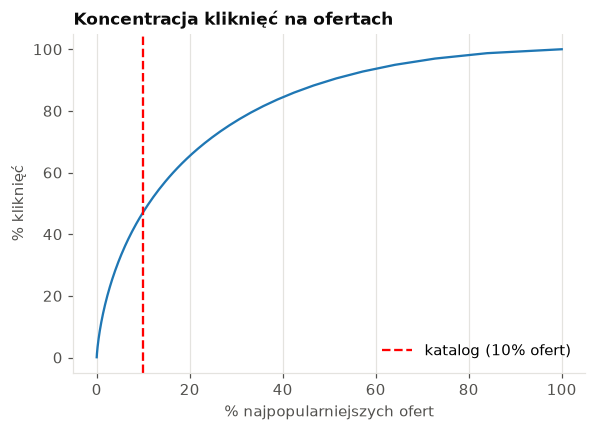

In [31]:
# jaki % kliknięć w train daje x% najpopularniejszych ofert
cum_share = pop.cumsum() / pop.sum()

plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, len(pop) + 1) / len(pop) * 100, cum_share.values * 100)
plt.axvline(10, color='red', linestyle='--', label='katalog (10% ofert)')
plt.title('Koncentracja kliknięć na ofertach')
plt.xlabel('% najpopularniejszych ofert')
plt.ylabel('% kliknięć')
plt.legend()
plt.grid()
plt.show()

## Metryki

In [32]:
def precision_recall(recs, k=10):
    precision, recall = [], []
    for user in eval_users:
        hits = len(set(recs[user][:k]) & test_items[user])
        precision.append(hits / k)
        recall.append(hits / len(test_items[user]))
    return np.mean(precision), np.mean(recall)

## Baseline

In [33]:
t0 = time.time()
pop_order = train["item"].value_counts().index
fit_time = time.time() - t0


def popularity(users, k=10, exclude_seen=False):
    if not exclude_seen:
        return {u: list(pop_order[:k]) for u in users}
    return {
        u: list(islice((i for i in pop_order if i not in train_items[u]), k))
        for u in users
    }

In [34]:
results = []
for label, exclude_seen in [("nie wykluczamy", False), ("wykluczamy", True)]:
    t0 = time.time()
    recs = popularity(eval_users, exclude_seen=exclude_seen)
    predict_time = time.time() - t0

    precision, recall = precision_recall(recs)
    results.append({
        "oferty z train": label,
        "Precision@10": precision,
        "Recall@10": recall,
        "czas treningu [s]": fit_time,
        "czas predykcji [s]": predict_time,
    })

results = pd.DataFrame(results).round(4)
print(results.to_string(index=False))

oferty z train  Precision@10  Recall@10  czas treningu [s]  czas predykcji [s]
nie wykluczamy        0.0020     0.0041             0.0075              0.0522
    wykluczamy        0.0014     0.0032             0.0075              0.1818


## 5. Prosty eksperyment Implicit ALS - baseline

Sprawdzenie działania jednej konfiguracji: 64 czynniki, 20 iteracji, sygnał `log1p(liczba kliknięć)` i ufność `1 + alpha × sygnał`.
Podobnie jak dla baseline'u oceniamy dwa warianty: dopuszczamy oferty kliknięte wcześniej w `train` albo je wykluczamy z rekomendacji. Wynik testowy służy tu do wstępnego sprawdzenia działania; nie dobieramy na nim parametrów.

In [36]:
from scipy.sparse import coo_matrix
from implicit.cpu.als import AlternatingLeastSquares

als_alpha = 40.0
als_users = pd.Index(train['user'].drop_duplicates())
als_items = pd.Index(train['item'].drop_duplicates())
als_counts = train.groupby(['user', 'item'], sort=False).size().reset_index(name='count')
als_confidence = 1.0 + als_alpha * np.log1p(als_counts['count'].to_numpy(dtype=np.float32))
als_matrix = coo_matrix(
    (als_confidence, (als_users.get_indexer(als_counts['user']),
                      als_items.get_indexer(als_counts['item']))),
    shape=(len(als_users), len(als_items)), dtype=np.float32,
).tocsr()

als_model = AlternatingLeastSquares(
    factors=64, regularization=0.01, iterations=20,
    alpha=1.0, random_state=42, num_threads=4,
)  # Ufność została już policzona w macierzy.
als_t0 = time.perf_counter()
als_model.fit(als_matrix, show_progress=True)
als_fit_time = time.perf_counter() - als_t0
#print(f'Trening ALS: {als_fit_time:.2f} s')

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:07<00:00,  2.63it/s]


In [37]:
als_eval_rows = als_users.get_indexer(eval_users)


def recommend_als(exclude_seen=False):
    recs = {}
    t0 = time.perf_counter()
    for start in range(0, len(eval_users), 256):
        batch_users = eval_users[start:start + 256]
        batch_rows = als_eval_rows[start:start + 256]
        batch_items, _ = als_model.recommend(
            batch_rows, als_matrix[batch_rows], N=10,
            filter_already_liked_items=exclude_seen,
        )
        recs.update({u: als_items[items].tolist() for u, items in zip(batch_users, batch_items)})
    return recs, time.perf_counter() - t0


als_results = []
for label, exclude_seen in [("nie wykluczamy", False), ("wykluczamy", True)]:
    recs, predict_time = recommend_als(exclude_seen)
    precision, recall = precision_recall(recs)
    if exclude_seen:
        als_excl_precision, als_excl_recall, als_excl_predict_time = precision, recall, predict_time
    else:
        als_recs, als_precision, als_recall, als_predict_time = recs, precision, recall, predict_time
    als_results.append({
        'model': 'Implicit ALS', 'oferty z train': label,
        'Precision@10': precision, 'Recall@10': recall,
        'czas treningu [s]': als_fit_time, 'czas predykcji [s]': predict_time,
    })
als_results = pd.DataFrame(als_results)
print(als_results.round(4).to_string(index=False))

       model oferty z train  Precision@10  Recall@10  czas treningu [s]  czas predykcji [s]
Implicit ALS nie wykluczamy        0.0511     0.1510              7.635              0.3196
Implicit ALS     wykluczamy        0.0307     0.0834              7.635              0.6317


## 6. Walidacja hiperparametrów ALS

Dotychczasowy model (`log1p`, alpha=40, factors=64, regularization=0.01, 20 iteracji) jest baseline’em ALS. Poniżej oceniamy tę samą konfigurację na walidacji i porównujemy ją z kandydatami.

Walidacja obejmuje ostatnie 20% okresu treningowego. Podział wykonujemy na `sample` przed filtrowaniem ofert, a katalog 10% najpopularniejszych ofert wybieramy wyłącznie z wcześniejszej części. Nie zawężamy ponownie już przefiltrowanego katalogu `train`. Test nie uczestniczy w wyborze parametrów. Dopuszczamy rekomendowanie ofert wcześniej klikniętych.

Badamy sygnał binarny i log1p, alpha, liczbę czynników, regularyzację i liczbę iteracji. W obrębie konfiguracji kontynuujemy trening tego samego modelu między checkpointami. Plateau Recall@10 służy do wczesnego zatrzymania — nie oznacza matematycznej zbieżności funkcji celu.

In [38]:
from itertools import product
from pathlib import Path
from datetime import datetime, timezone
import json

ALS_BASELINE_PARAMS = dict(signal='log1p', alpha=40.0, factors=64, regularization=0.01)
ALS_SIGNALS = ['binary', 'log1p']
ALS_ALPHAS = [40.0, 100.0]
ALS_FACTORS = [64, 128, 256, 512]
ALS_REGULARIZATIONS = [0.1]
ALS_CHECKPOINTS = [1, 2, 3, 5, 10, 20]
ALS_PATIENCE = 2
ALS_MIN_ITERATIONS = 3
ALS_MIN_DELTA = 1e-5
ALS_SEED = 42
ALS_BATCH_SIZE = 256

# Dane przed filtrowaniem katalogu; wyłącznie okres wcześniejszy niż test.
als_validation_pool = sample[sample['timestamp'] < t_split]
als_validation_cutoff = als_validation_pool['timestamp'].quantile(0.8)
als_inner_train = als_validation_pool[als_validation_pool['timestamp'] < als_validation_cutoff]
als_validation = als_validation_pool[als_validation_pool['timestamp'] >= als_validation_cutoff]
als_validation_pop = als_inner_train['item'].value_counts()
als_validation_catalog = als_validation_pop.head(max(1, int(len(als_validation_pop) * 0.1))).index
als_inner_train = als_inner_train[als_inner_train['item'].isin(als_validation_catalog)]
als_validation = als_validation[als_validation['item'].isin(als_validation_catalog)]

als_search_dir = Path('results') / datetime.now(timezone.utc).strftime('als_validation_%Y%m%dT%H%M%S%fZ')
als_search_dir.mkdir(parents=True, exist_ok=False)
print('Próg walidacji:', als_validation_cutoff)
print('Interakcje treningowe:', len(als_inner_train), 'walidacyjne:', len(als_validation))
print('Wyniki:', als_search_dir)

Próg walidacji: 2020-02-14 18:13:49
Interakcje treningowe: 541544 walidacyjne: 103224
Wyniki: results/als_validation_20261019T134624094471Z


In [39]:
def prepare_als_data(interactions, future):
    users = pd.Index(interactions['user'].drop_duplicates())
    items = pd.Index(interactions['item'].drop_duplicates())
    if len(items) < 10:
        raise ValueError('Katalog musi zawierać przynajmniej 10 ofert.')
    counts = interactions.groupby(['user', 'item'], sort=False).size().reset_index(name='count')
    matrix = coo_matrix(
        (counts['count'].to_numpy(dtype=np.float32),
         (users.get_indexer(counts['user']), items.get_indexer(counts['item']))),
        shape=(len(users), len(items)), dtype=np.float32,
    ).tocsr()
    future = future[future['item'].isin(items)]
    targets = future.groupby('user')['item'].agg(set)
    evaluation_users = users.intersection(targets.index, sort=False)
    if evaluation_users.empty:
        raise ValueError('Brak wspólnych użytkowników w treningu i zbiorze oceny.')
    return dict(
        counts=matrix, users=users, items=items,
        eval_rows=users.get_indexer(evaluation_users),
        targets=[set(items.get_indexer(list(targets[u]))) for u in evaluation_users],
    )


def make_als_confidence(counts, signal, alpha):
    if alpha <= 0:
        raise ValueError('alpha musi być dodatnie.')
    matrix = counts.copy()
    if signal == 'binary':
        matrix.data[:] = 1.0
    elif signal == 'log1p':
        np.log1p(matrix.data, out=matrix.data)
    else:
        raise ValueError(f'Nieznany sygnał: {signal}')
    matrix.data *= alpha
    matrix.data += 1.0  # jawna ufność; w modelu alpha=1
    return matrix


def evaluate_als(model, matrix, data, exclude_seen=False):
    precision_sum = recall_sum = recommend_seconds = 0.0
    for start in range(0, len(data['eval_rows']), ALS_BATCH_SIZE):
        rows = data['eval_rows'][start:start + ALS_BATCH_SIZE]
        t0 = time.perf_counter()
        recommendations, _ = model.recommend(
            rows, matrix[rows], N=10, filter_already_liked_items=exclude_seen,
        )
        recommend_seconds += time.perf_counter() - t0
        for offset, rec in enumerate(recommendations):
            target = data['targets'][start + offset]
            hits = len(set(rec) & target)
            precision_sum += hits / 10
            recall_sum += hits / len(target)
    n = len(data['eval_rows'])
    return {'Precision@10': precision_sum / n, 'Recall@10': recall_sum / n,
            'recommend_seconds': recommend_seconds}


def fit_als(data, params, checkpoints, early_stopping=False):
    checkpoints = list(checkpoints)
    if not checkpoints or checkpoints[0] <= 0 or checkpoints != sorted(set(checkpoints)):
        raise ValueError('Checkpointy muszą być dodatnie i ściśle rosnące.')
    matrix = make_als_confidence(data['counts'], params['signal'], params['alpha'])
    model = AlternatingLeastSquares(
        factors=params['factors'], regularization=params['regularization'],
        alpha=1.0, random_state=ALS_SEED, num_threads=4,
    )
    history, completed, stale = [], 0, 0
    fit_seconds, patience_score = 0.0, -np.inf
    for checkpoint in checkpoints:
        model.iterations = checkpoint - completed
        t0 = time.perf_counter()
        # implicit.cpu.als zachowuje istniejące faktory przy kolejnym fit.
        model.fit(matrix, show_progress=False)
        fit_seconds += time.perf_counter() - t0
        completed = checkpoint
        metrics = evaluate_als(model, matrix, data)
        history.append({**params, 'iterations': completed, **metrics, 'fit_seconds': fit_seconds})
        if metrics['Recall@10'] > patience_score + ALS_MIN_DELTA:
            patience_score, stale = metrics['Recall@10'], 0
        elif completed >= ALS_MIN_ITERATIONS:
            stale += 1
        if early_stopping and completed >= ALS_MIN_ITERATIONS and stale >= ALS_PATIENCE:
            break
    return model, matrix, history


als_validation_data = prepare_als_data(als_inner_train, als_validation)
print('Macierz walidacyjnego treningu:', als_validation_data['counts'].shape)
print('Użytkownicy do oceny:', len(als_validation_data['eval_rows']))

Macierz walidacyjnego treningu: (84163, 10909)
Użytkownicy do oceny: 15139


### Baseline ALS na walidacji i przeszukiwanie konfiguracji

Najpierw trenujemy konfigurację baseline’u od nowa, wyłącznie na wewnętrznym treningu. Następnie sprawdzamy 16 konfiguracji (2 sygnały × 2 wartości alpha × 4 liczby czynników, regularyzacja 0,1) i rosnące checkpointy iteracji od 1 do 20. Wstępne eksperymenty pokazały, że więcej czynników wyraźnie pomaga, najlepsze wyniki dają 2–3 iteracje, a regularyzacja prawie nie ma wpływu. Wybieramy najwyższy Recall@10, następnie Precision@10, a przy remisie mniej iteracji. Limit 20 iteracji bez plateau oznacza, że nie zaobserwowano zatrzymania w tym zakresie.

In [40]:
als_baseline_val_model, als_baseline_val_matrix, als_baseline_val_history = fit_als(
    als_validation_data, ALS_BASELINE_PARAMS, checkpoints=[20],
)
als_baseline_val_result = als_baseline_val_history[-1]
pd.DataFrame([als_baseline_val_result]).to_csv(als_search_dir / 'baseline_validation.csv', index=False)
display(pd.DataFrame([{'model': 'ALS baseline', **als_baseline_val_result}]))
del als_baseline_val_model, als_baseline_val_matrix

,model,signal,alpha,factors,regularization,iterations,Precision@10,Recall@10,recommend_seconds,fit_seconds
0,ALS baseline,log1p,40.0,64,0.01,20,0.057679,0.189393,0.187028,6.446225


In [41]:
als_search_history, als_search_summary = [], []
for signal, alpha, factors, regularization in product(
    ALS_SIGNALS, ALS_ALPHAS, ALS_FACTORS, ALS_REGULARIZATIONS
):
    params = dict(signal=signal, alpha=alpha, factors=factors, regularization=regularization)
    candidate_model, candidate_matrix, history = fit_als(
        als_validation_data, params, ALS_CHECKPOINTS, early_stopping=True,
    )
    als_search_history.extend(history)
    best_checkpoint = min(history, key=lambda r: (-r['Recall@10'], -r['Precision@10'], r['iterations']))
    summary = {**best_checkpoint, 'iterations_run': history[-1]['iterations'],
               'total_fit_seconds': history[-1]['fit_seconds'],
               'stop_reason': 'validation_plateau' if len(history) < len(ALS_CHECKPOINTS) else 'iteration_limit'}
    als_search_summary.append(summary)
    pd.DataFrame(als_search_history).to_csv(als_search_dir / 'validation_history.csv', index=False)
    pd.DataFrame(als_search_summary).to_csv(als_search_dir / 'validation_summary.csv', index=False)
    print(params, 'Recall@10:', round(summary['Recall@10'], 5),
          'najlepsza iteracja:', summary['iterations'])
    del candidate_model, candidate_matrix

# Baseline zawsze pozostaje kandydatem, nawet jeśli early stopping pominąłby jego checkpoint.
als_validation_ranking = pd.DataFrame([als_baseline_val_result, *als_search_summary]).sort_values(
    ['Recall@10', 'Precision@10', 'iterations'], ascending=[False, False, True], kind='stable'
)
display(als_validation_ranking)
als_best_validation = als_validation_ranking.iloc[0]
als_selected_params = dict(
    signal=str(als_best_validation['signal']), alpha=float(als_best_validation['alpha']),
    factors=int(als_best_validation['factors']),
    regularization=float(als_best_validation['regularization']),
)
als_selected_iterations = int(als_best_validation['iterations'])
als_validation_comparison = pd.DataFrame([
    {'model': 'ALS baseline', **als_baseline_val_result},
    {'model': 'ALS selected', **als_best_validation.to_dict()},
])
display(als_validation_comparison)
als_validation_comparison.to_csv(als_search_dir / 'validation_comparison.csv', index=False)
(als_search_dir / 'selected_config.json').write_text(json.dumps({
    **als_selected_params, 'iterations': als_selected_iterations, 'seed': ALS_SEED,
    'validation_cutoff': str(als_validation_cutoff), 'test_cutoff': str(t_split),
    'grid': dict(signals=ALS_SIGNALS, alphas=ALS_ALPHAS, factors=ALS_FACTORS,
                 regularizations=ALS_REGULARIZATIONS, checkpoints=ALS_CHECKPOINTS),
    'early_stopping': dict(patience=ALS_PATIENCE, min_delta=ALS_MIN_DELTA,
                           min_iterations=ALS_MIN_ITERATIONS),
}, indent=2), encoding='utf-8')

{'signal': 'binary', 'alpha': 40.0, 'factors': 64, 'regularization': 0.1} Recall@10: 0.23602 najlepsza iteracja: 3
{'signal': 'binary', 'alpha': 40.0, 'factors': 128, 'regularization': 0.1} Recall@10: 0.27797 najlepsza iteracja: 3
{'signal': 'binary', 'alpha': 40.0, 'factors': 256, 'regularization': 0.1} Recall@10: 0.29231 najlepsza iteracja: 3
{'signal': 'binary', 'alpha': 40.0, 'factors': 512, 'regularization': 0.1} Recall@10: 0.29383 najlepsza iteracja: 20
{'signal': 'binary', 'alpha': 100.0, 'factors': 64, 'regularization': 0.1} Recall@10: 0.26304 najlepsza iteracja: 3
{'signal': 'binary', 'alpha': 100.0, 'factors': 128, 'regularization': 0.1} Recall@10: 0.28256 najlepsza iteracja: 3
{'signal': 'binary', 'alpha': 100.0, 'factors': 256, 'regularization': 0.1} Recall@10: 0.2892 najlepsza iteracja: 20
{'signal': 'binary', 'alpha': 100.0, 'factors': 512, 'regularization': 0.1} Recall@10: 0.29048 najlepsza iteracja: 20
{'signal': 'log1p', 'alpha': 40.0, 'factors': 64, 'regularization': 

,signal,alpha,factors,regularization,iterations,Precision@10,Recall@10,recommend_seconds,fit_seconds,iterations_run,total_fit_seconds,stop_reason
12,log1p,40.0,512,0.10,20,0.082747,0.298907,0.314204,188.860418,20.0,188.860418,iteration_limit
11,log1p,40.0,256,0.10,3,0.082892,0.297867,0.217703,9.959122,10.0,32.955937,validation_plateau
16,log1p,100.0,512,0.10,20,0.080864,0.294348,0.317617,188.582760,20.0,188.582760,iteration_limit
4,binary,40.0,512,0.10,20,0.081135,0.293829,0.310860,186.587107,20.0,186.587107,iteration_limit
3,binary,40.0,256,0.10,3,0.081148,0.292307,0.235613,10.072955,10.0,33.531819,validation_plateau
15,log1p,100.0,256,0.10,20,0.080276,0.292230,0.223597,65.806111,20.0,65.806111,iteration_limit
8,binary,100.0,512,0.10,20,0.079556,0.290484,0.309005,186.862309,20.0,186.862309,iteration_limit
7,binary,100.0,256,0.10,20,0.079107,0.289199,0.231143,66.140707,20.0,66.140707,iteration_limit
14,log1p,100.0,128,0.10,3,0.079034,0.287050,0.197527,3.369808,10.0,11.166641,validation_plateau
6,binary,100.0,128,0.10,3,0.077502,0.282560,0.198029,3.389318,10.0,11.199241,validation_plateau


,model,signal,alpha,factors,regularization,iterations,Precision@10,Recall@10,recommend_seconds,fit_seconds,iterations_run,total_fit_seconds,stop_reason
0,ALS baseline,log1p,40.0,64,0.01,20,0.057679,0.189393,0.187028,6.446225,NaN,NaN,NaN
1,ALS selected,log1p,40.0,512,0.10,20,0.082747,0.298907,0.314204,188.860418,20.0,188.860418,iteration_limit


605

### Końcowe porównanie z baseline’em ALS na teście

Trenujemy wybraną konfigurację od początku na całym istniejącym `train`, przez liczbę iteracji wybraną na walidacji. Wynik porównujemy z wcześniejszym baseline’em ALS na tych samych użytkownikach i celach, w obu wariantach: z dopuszczeniem i z wykluczeniem ofert klikniętych w `train`. Konfigurację wybieraliśmy w wariancie bez wykluczania. Nie używamy tego porównania do dalszego strojenia. Model i mapowania identyfikatorów pozostają w zmiennych `als_tuned_model` i `als_final_data`.

In [42]:
als_final_data = prepare_als_data(train, test)
als_tuned_model, als_tuned_matrix, als_tuned_history = fit_als(
    als_final_data, als_selected_params, checkpoints=[als_selected_iterations],
)
als_tuned_metrics = als_tuned_history[-1]
als_tuned_excl_metrics = {
    **als_tuned_metrics,
    **evaluate_als(als_tuned_model, als_tuned_matrix, als_final_data, exclude_seen=True),
}
als_test_comparison = pd.DataFrame([
    {'model': 'ALS baseline', 'oferty z train': 'nie wykluczamy', **ALS_BASELINE_PARAMS, 'iterations': 20,
     'Precision@10': als_precision, 'Recall@10': als_recall,
     'fit_seconds': als_fit_time, 'recommend_seconds': als_predict_time},
    {'model': 'ALS tuned', 'oferty z train': 'nie wykluczamy', **als_tuned_metrics},
    {'model': 'ALS baseline', 'oferty z train': 'wykluczamy', **ALS_BASELINE_PARAMS, 'iterations': 20,
     'Precision@10': als_excl_precision, 'Recall@10': als_excl_recall,
     'fit_seconds': als_fit_time, 'recommend_seconds': als_excl_predict_time},
    {'model': 'ALS tuned', 'oferty z train': 'wykluczamy', **als_tuned_excl_metrics},
])
display(als_test_comparison)
als_test_comparison.to_csv(als_search_dir / 'test_comparison.csv', index=False)

,model,oferty z train,signal,alpha,factors,regularization,iterations,Precision@10,Recall@10,fit_seconds,recommend_seconds
0,ALS baseline,nie wykluczamy,log1p,40.0,64,0.01,20,0.051134,0.151049,7.634979,0.319620
1,ALS tuned,nie wykluczamy,log1p,40.0,512,0.10,20,0.075091,0.249808,215.463157,0.496275
2,ALS baseline,wykluczamy,log1p,40.0,64,0.01,20,0.030716,0.083438,7.634979,0.631749
3,ALS tuned,wykluczamy,log1p,40.0,512,0.10,20,0.040693,0.125727,215.463157,0.787331


## 7. Item-kNN (BM25)

Model sąsiedztwa ofert. Macierz kliknięć użytkownik × oferta ważymy BM25 (`K1=1.2`, `B=0.75`), a podobieństwo dwóch ofert liczymy z ich kolumn. Każda oferta zachowuje `K` najbardziej podobnych sąsiadów. Wynik oferty dla użytkownika to suma jej podobieństw do ofert klikniętych w treningu, ważona liczbą kliknięć.

Liczbę sąsiadów `K` wybieramy na tej samej walidacji co ALS, w wariancie bez wykluczania. Test nie uczestniczy w wyborze. Do oceny używamy `evaluate_als`, bo item-kNN z `implicit` ma ten sam interfejs `recommend`.

In [43]:
from implicit.nearest_neighbours import BM25Recommender

KNN_KS = [20, 50, 100, 200, 500]
KNN_K1, KNN_B = 1.2, 0.75

knn_search = []
for k in KNN_KS:
    model = BM25Recommender(K=k, K1=KNN_K1, B=KNN_B, num_threads=4)
    t0 = time.perf_counter()
    model.fit(als_validation_data['counts'], show_progress=False)
    fit_seconds = time.perf_counter() - t0
    metrics = evaluate_als(model, als_validation_data['counts'], als_validation_data)
    knn_search.append({'K': k, **metrics, 'fit_seconds': fit_seconds})
    del model
knn_search = pd.DataFrame(knn_search).sort_values(
    ['Recall@10', 'Precision@10', 'K'], ascending=[False, False, True], kind='stable'
)
knn_search.to_csv(als_search_dir / 'knn_validation.csv', index=False)
display(knn_search)
knn_selected_k = int(knn_search.iloc[0]['K'])
print('Wybrane K:', knn_selected_k)

/Users/websensa/GolandProjects/awesomeProject/.venv/lib/python3.12/site-packages/implicit/utils.py:164: ParameterWarning: Method expects CSR input, and was passed coo_matrix instead. Converting to CSR took 0.004716157913208008 seconds
  warnings.warn(
/Users/websensa/GolandProjects/awesomeProject/.venv/lib/python3.12/site-packages/implicit/utils.py:164: ParameterWarning: Method expects CSR input, and was passed coo_matrix instead. Converting to CSR took 0.002556324005126953 seconds
  warnings.warn(
/Users/websensa/GolandProjects/awesomeProject/.venv/lib/python3.12/site-packages/implicit/utils.py:164: ParameterWarning: Method expects CSR input, and was passed coo_matrix instead. Converting to CSR took 0.0025708675384521484 seconds
  warnings.warn(
/Users/websensa/GolandProjects/awesomeProject/.venv/lib/python3.12/site-packages/implicit/utils.py:164: ParameterWarning: Method expects CSR input, and was passed coo_matrix instead. Converting to CSR took 0.0025899410247802734 seconds
  warni

,K,Precision@10,Recall@10,recommend_seconds,fit_seconds
4,500,0.085329,0.301706,0.567461,0.539074
3,200,0.085309,0.301611,0.443486,0.234141
1,50,0.085369,0.301414,0.320505,0.134276
2,100,0.085276,0.301376,0.375731,0.174858
0,20,0.084887,0.299843,0.287028,0.098971


Wybrane K: 500


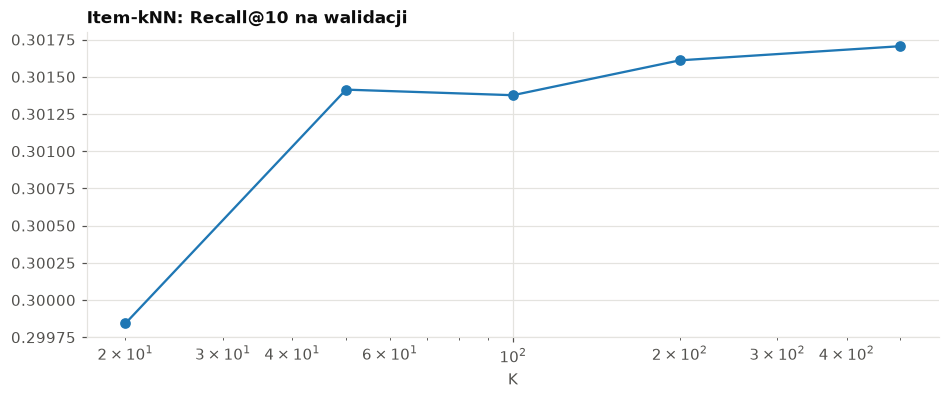

In [44]:
knn_search.sort_values('K').plot(x='K', y='Recall@10', marker='o', logx=True, grid=True, legend=False,
                                 title='Item-kNN: Recall@10 na walidacji')
plt.show()

### Item-kNN na teście

Trenujemy model z wybranym `K` na całym `train` i oceniamy go na tych samych użytkownikach i celach co ALS, w obu wariantach.

In [45]:
knn_model = BM25Recommender(K=knn_selected_k, K1=KNN_K1, B=KNN_B, num_threads=4)
t0 = time.perf_counter()
knn_model.fit(als_final_data['counts'], show_progress=False)
knn_fit_time = time.perf_counter() - t0

knn_name = f'Item-kNN BM25 (K={knn_selected_k})'
knn_results = []
for label, exclude_seen in [('nie wykluczamy', False), ('wykluczamy', True)]:
    metrics = evaluate_als(knn_model, als_final_data['counts'], als_final_data, exclude_seen=exclude_seen)
    knn_results.append({
        'model': knn_name, 'oferty z train': label,
        'Precision@10': metrics['Precision@10'], 'Recall@10': metrics['Recall@10'],
        'czas treningu [s]': knn_fit_time, 'czas predykcji [s]': metrics['recommend_seconds'],
    })
knn_results = pd.DataFrame(knn_results)
print(knn_results.round(4).to_string(index=False))

/Users/websensa/GolandProjects/awesomeProject/.venv/lib/python3.12/site-packages/implicit/utils.py:164: ParameterWarning: Method expects CSR input, and was passed coo_matrix instead. Converting to CSR took 0.0062448978424072266 seconds
  warnings.warn(


                model oferty z train  Precision@10  Recall@10  czas treningu [s]  czas predykcji [s]
Item-kNN BM25 (K=500) nie wykluczamy        0.0778     0.2542             0.5598              0.8414
Item-kNN BM25 (K=500)     wykluczamy        0.0423     0.1271             0.5598              0.8379


## 8. EASE


Jedyny hiperparametr `λ` wybieramy na tej samej walidacji co pozostałe modele, w wariancie bez wykluczania.

,lambda,Precision@10,Recall@10,recommend_seconds,fit_seconds
1,10,0.073710,0.244327,1.649736,10.440977
2,20,0.073968,0.244062,1.662021,10.666045
0,5,0.073314,0.243448,1.651913,11.259973
3,50,0.074404,0.241849,1.660335,10.568170
4,100,0.074311,0.239414,1.714882,10.462148
5,200,0.073103,0.233606,1.688214,10.755176
6,500,0.070183,0.224423,1.721776,10.499105


Wybrane lambda: 10.0


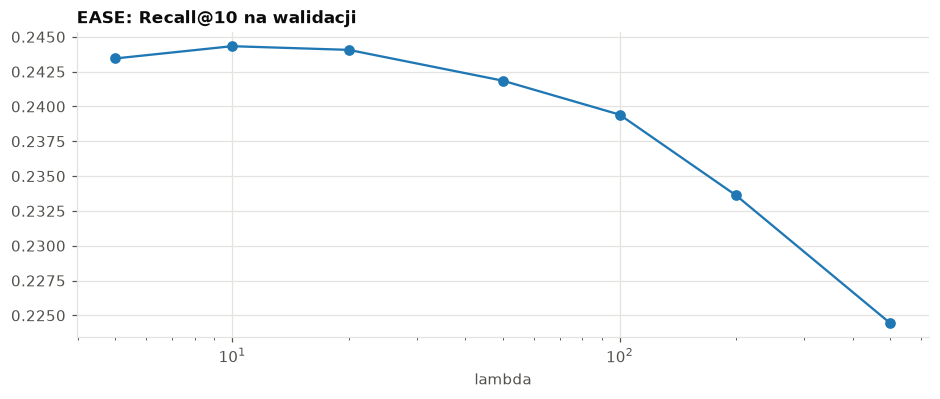

In [46]:
class EASE:
    def __init__(self, regularization=50.0):
        self.regularization = regularization

    def fit(self, user_items):
        X = user_items.copy()
        X.data[:] = 1.0
        G = (X.T @ X).toarray().astype(np.float64)
        G[np.diag_indices_from(G)] += self.regularization
        P = np.linalg.inv(G)
        B = -P / np.diag(P)
        B[np.diag_indices_from(B)] = 0.0
        self.item_weights = B.astype(np.float32)
        return self

    def recommend(self, userid, user_items, N=10, filter_already_liked_items=True):
        X = user_items.copy()
        X.data[:] = 1.0
        scores = np.asarray(X @ self.item_weights)
        if filter_already_liked_items:
            scores[X.nonzero()] = -np.inf
        top = np.argpartition(-scores, N, axis=1)[:, :N]
        order = np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1)
        ids = np.take_along_axis(top, order, axis=1)
        top_scores = np.take_along_axis(scores, ids, axis=1)
        if np.isscalar(userid):
            return ids[0], top_scores[0]
        return ids, top_scores


EASE_LAMBDAS = [5, 10, 20, 50, 100, 200, 500]

ease_search = []
for lam in EASE_LAMBDAS:
    t0 = time.perf_counter()
    model = EASE(regularization=lam).fit(als_validation_data['counts'])
    fit_seconds = time.perf_counter() - t0
    metrics = evaluate_als(model, als_validation_data['counts'], als_validation_data)
    ease_search.append({'lambda': lam, **metrics, 'fit_seconds': fit_seconds})
    del model
ease_search = pd.DataFrame(ease_search).sort_values(
    ['Recall@10', 'Precision@10', 'lambda'], ascending=[False, False, False], kind='stable'
)
ease_search.to_csv(als_search_dir / 'ease_validation.csv', index=False)
display(ease_search)
ease_selected_lambda = float(ease_search.iloc[0]['lambda'])
print('Wybrane lambda:', ease_selected_lambda)
ease_search.sort_values('lambda').plot(x='lambda', y='Recall@10', marker='o', logx=True, grid=True, legend=False,
                                       title='EASE: Recall@10 na walidacji')
plt.show()

### EASE na teście

Trenujemy EASE z wybranym `λ` na całym `train` i oceniamy na tych samych użytkownikach i celach co pozostałe modele, w obu wariantach.

In [47]:
t0 = time.perf_counter()
ease_model = EASE(regularization=ease_selected_lambda).fit(als_final_data['counts'])
ease_fit_time = time.perf_counter() - t0

ease_name = f'EASE (λ={ease_selected_lambda:g})'
ease_results = []
for label, exclude_seen in [('nie wykluczamy', False), ('wykluczamy', True)]:
    metrics = evaluate_als(ease_model, als_final_data['counts'], als_final_data, exclude_seen=exclude_seen)
    ease_results.append({
        'model': ease_name, 'oferty z train': label,
        'Precision@10': metrics['Precision@10'], 'Recall@10': metrics['Recall@10'],
        'czas treningu [s]': ease_fit_time, 'czas predykcji [s]': metrics['recommend_seconds'],
    })
ease_results = pd.DataFrame(ease_results)
print(ease_results.round(4).to_string(index=False))

      model oferty z train  Precision@10  Recall@10  czas treningu [s]  czas predykcji [s]
EASE (λ=10) nie wykluczamy        0.0682     0.2102            12.9797              2.4084
EASE (λ=10)     wykluczamy        0.0384     0.1179            12.9797              2.4402


## 9. Czas pojedynczej predykcji

Dotychczasowe czasy predykcji dotyczą wszystkich użytkowników ewaluacji naraz, liczonych w batchach. Tu mierzymy pojedyncze wywołanie dla jednego użytkownika, bez batchowania, na losowej próbie 1000 użytkowników ewaluacji. Podajemy medianę i 95. percentyl w milisekundach.

In [48]:
LATENCY_USERS = 1000
latency_users = eval_users[
    np.random.default_rng(42).choice(len(eval_users), LATENCY_USERS, replace=False)
]
als_row_of = dict(zip(eval_users, als_eval_rows))
final_row_of = dict(zip(eval_users, als_final_data['users'].get_indexer(eval_users)))


def single_latency(recommend_one):
    times = []
    for user in latency_users:
        t0 = time.perf_counter()
        recommend_one(user)
        times.append(time.perf_counter() - t0)
    times = np.array(times) * 1000
    return np.median(times), np.percentile(times, 95)


def implicit_one(model, matrix, row_of, exclude_seen):
    def recommend_one(user):
        row = row_of[user]
        return model.recommend(row, matrix[row], N=10, filter_already_liked_items=exclude_seen)
    return recommend_one


latency = []
for label, exclude_seen in [('nie wykluczamy', False), ('wykluczamy', True)]:
    candidates = {
        'Popularność': lambda user: popularity([user], exclude_seen=exclude_seen),
        'Implicit ALS': implicit_one(als_model, als_matrix, als_row_of, exclude_seen),
        'Implicit ALS (tuned)': implicit_one(als_tuned_model, als_tuned_matrix, final_row_of, exclude_seen),
        knn_name: implicit_one(knn_model, als_final_data['counts'], final_row_of, exclude_seen),
        ease_name: implicit_one(ease_model, als_final_data['counts'], final_row_of, exclude_seen),
    }
    for name, recommend_one in candidates.items():
        median_ms, p95_ms = single_latency(recommend_one)
        latency.append({'model': name, 'oferty z train': label,
                        'pojedyncza predykcja, mediana [ms]': median_ms,
                        'pojedyncza predykcja, p95 [ms]': p95_ms})
latency = pd.DataFrame(latency)
print(latency.round(3).to_string(index=False))

                model oferty z train  pojedyncza predykcja, mediana [ms]  pojedyncza predykcja, p95 [ms]
          Popularność nie wykluczamy                               0.002                           0.003
         Implicit ALS nie wykluczamy                               0.066                           0.092
 Implicit ALS (tuned) nie wykluczamy                               0.573                           0.846
Item-kNN BM25 (K=500) nie wykluczamy                               0.039                           0.140
          EASE (λ=10) nie wykluczamy                               0.152                           0.212
          Popularność     wykluczamy                               0.014                           0.022
         Implicit ALS     wykluczamy                               0.075                           0.081
 Implicit ALS (tuned)     wykluczamy                               0.561                           0.703
Item-kNN BM25 (K=500)     wykluczamy                   

## 10. Porównanie wszystkich metod

**Dane i podział**: 10% losowych użytkowników, katalog zawężony do 10% najpopularniejszych ofert z `train`. Podział czasowy: pierwsze 80% okresu to `train`, ostatnie 20% to `test`. Hiperparametry dobieramy na walidacji, czyli ostatnich 20% okresu treningowego. Oceniamy użytkowników obecnych w obu zbiorach, a celem są oferty z katalogu kliknięte w teście. Każda metoda zwraca top-10, liczymy Precision@10 i Recall@10, w dwóch wariantach: z dopuszczeniem i z wykluczeniem ofert klikniętych w `train`.

**Czasy w tabeli**: *trening* to dopasowanie modelu na całym `train`, a *na interakcję* to ten czas podzielony przez liczbę interakcji w `train`. *Ewaluacja* to wygenerowanie top-10 dla wszystkich użytkowników ewaluacji w batchach, a *na użytkownika* to ten czas podzielony przez ich liczbę. *Pojedyncza predykcja* to osobne wywołanie dla jednego użytkownika (sekcja 9).

In [53]:
def data_size(name, df):
    return {'zbiór': name, 'użytkownicy': df['user'].nunique(),
            'oferty': df['item'].nunique(), 'interakcje': len(df)}


summary_data = pd.DataFrame([
    data_size('wszystkie kliknięcia', clicks),
    data_size('próbka 10% użytkowników', sample),
    data_size('train (katalog 10% ofert)', train),
    data_size('test (katalog 10% ofert)', test),
    {'zbiór': 'użytkownicy w ewaluacji', 'użytkownicy': len(eval_users),
     'oferty': len(catalog), 'interakcje': np.nan},
])
display(summary_data)

als_tuned_rows = als_test_comparison[als_test_comparison['model'] == 'ALS tuned'].rename(columns={
    'fit_seconds': 'czas treningu [s]', 'recommend_seconds': 'czas predykcji [s]',
}).assign(model='Implicit ALS (tuned)')
base_columns = ['model', 'oferty z train', 'Precision@10', 'Recall@10',
                'czas treningu [s]', 'czas predykcji [s]']
comparison = pd.concat([
    results.assign(model='Popularność'), als_results, als_tuned_rows,
    knn_results, ease_results,
])[base_columns].rename(columns={'czas predykcji [s]': 'czas ewaluacji [s]'})

comparison['czas treningu na interakcję [µs]'] = comparison['czas treningu [s]'] / len(train) * 1e6
comparison['czas ewaluacji na użytkownika [ms]'] = comparison['czas ewaluacji [s]'] / len(eval_users) * 1e3
comparison = comparison.merge(latency, on=['model', 'oferty z train'], how='left')
comparison = comparison.assign(**{
    'użytkownicy train': train['user'].nunique(), 'oferty': len(catalog),
    'interakcje train': len(train), 'użytkownicy ewaluacji': len(eval_users),
})
comparison = comparison.sort_values(
    ['oferty z train', 'Recall@10'], ascending=[True, False], kind='stable'
).reset_index(drop=True)
summary_data.to_csv(als_search_dir / 'summary_data.csv', index=False)
comparison.to_csv(als_search_dir / 'comparison.csv', index=False)
display(comparison.round(4))

,zbiór,użytkownicy,oferty,interakcje
0,wszystkie kliknięcia,1479598,155706,17774107.0
1,próbka 10% użytkowników,147960,118382,1783094.0
2,train (katalog 10% ofert),97199,11377,673057.0
3,test (katalog 10% ofert),34321,11134,132844.0
4,użytkownicy w ewaluacji,20507,11377,NaN


,model,oferty z train,Precision@10,Recall@10,czas treningu [s],czas ewaluacji [s],czas treningu na interakcję [µs],czas ewaluacji na użytkownika [ms],"pojedyncza predykcja, mediana [ms]","pojedyncza predykcja, p95 [ms]",użytkownicy train,oferty,interakcje train,użytkownicy ewaluacji
0,Item-kNN BM25 (K=500),nie wykluczamy,0.0778,0.2542,0.5598,0.8414,0.8317,0.0410,0.0389,0.1401,97199,11377,673057,20507
1,Implicit ALS (tuned),nie wykluczamy,0.0751,0.2498,215.4632,0.4963,320.1262,0.0242,0.5732,0.8459,97199,11377,673057,20507
2,EASE (λ=10),nie wykluczamy,0.0682,0.2102,12.9797,2.4084,19.2848,0.1174,0.1524,0.2115,97199,11377,673057,20507
3,Implicit ALS,nie wykluczamy,0.0511,0.1510,7.6350,0.3196,11.3437,0.0156,0.0658,0.0919,97199,11377,673057,20507
4,Popularność,nie wykluczamy,0.0020,0.0041,0.0075,0.0522,0.0111,0.0025,0.0016,0.0031,97199,11377,673057,20507
5,Item-kNN BM25 (K=500),wykluczamy,0.0423,0.1271,0.5598,0.8379,0.8317,0.0409,0.0336,0.0910,97199,11377,673057,20507
6,Implicit ALS (tuned),wykluczamy,0.0407,0.1257,215.4632,0.7873,320.1262,0.0384,0.5615,0.7030,97199,11377,673057,20507
7,EASE (λ=10),wykluczamy,0.0384,0.1179,12.9797,2.4402,19.2848,0.1190,0.1747,0.2385,97199,11377,673057,20507
8,Implicit ALS,wykluczamy,0.0307,0.0834,7.6350,0.6317,11.3437,0.0308,0.0750,0.0812,97199,11377,673057,20507
9,Popularność,wykluczamy,0.0014,0.0032,0.0075,0.1818,0.0111,0.0089,0.0136,0.0223,97199,11377,673057,20507


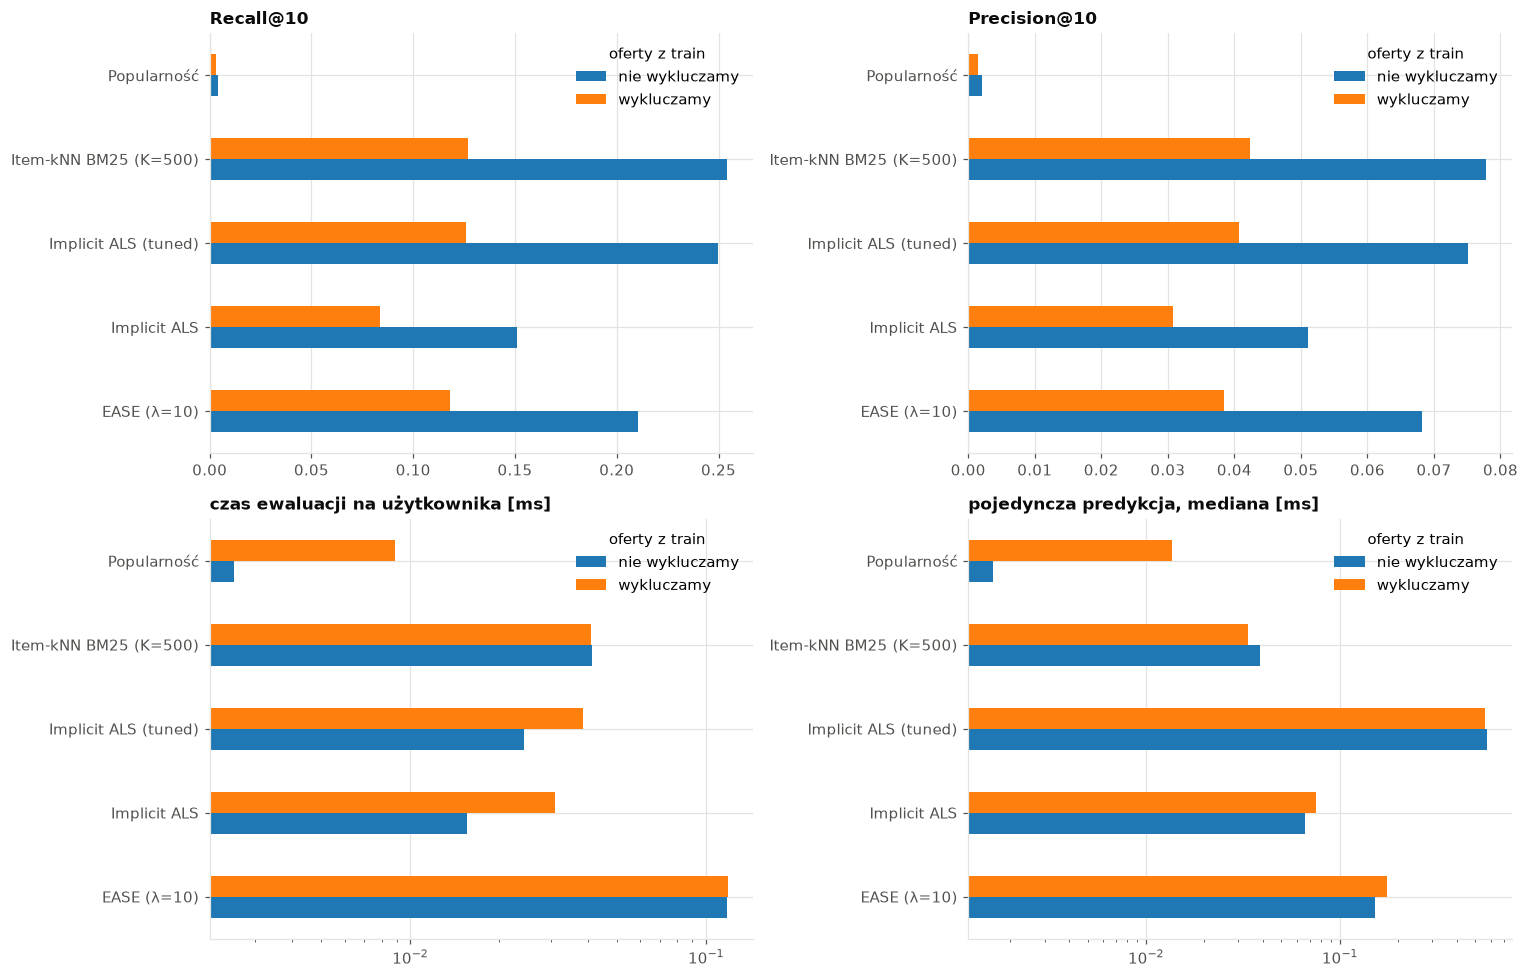

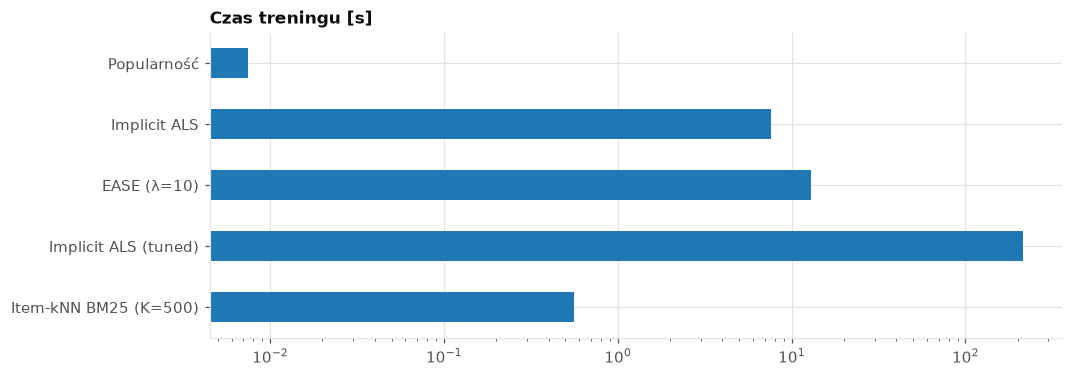

In [54]:
columns = ['Recall@10', 'Precision@10', 'czas ewaluacji na użytkownika [ms]', 'pojedyncza predykcja, mediana [ms]']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, columns):
    comparison.pivot_table(index='model', columns='oferty z train', values=col).plot.barh(ax=ax)
    ax.set_title(col)
    ax.set_ylabel('')
axes[1, 0].set_xscale('log')
axes[1, 1].set_xscale('log')
plt.tight_layout()
plt.show()

comparison[comparison['oferty z train'] == 'nie wykluczamy'].plot.barh(
    x='model', y='czas treningu [s]', logx=True, legend=False, title='Czas treningu [s]'
)
plt.ylabel('')
plt.show()

## 11. Wpływ wielkości zbioru (Item-kNN)

Najlepszy model, Item-kNN BM25 z `K` wybranym w sekcji 7, trenujemy i testujemy na coraz większych zbiorach. W każdej skali bierzemy ten sam ułamek losowych użytkowników i najpopularniejszych ofert w katalogu: 10% (jak w głównym eksperymencie, kontrola), 25%, 50%, 75% i 100%. Podział czasowy, katalog i ewaluacja są takie same jak wcześniej. Hiperparametrów nie stroimy ponownie.

In [51]:
import warnings
warnings.filterwarnings('ignore', message='Method expects CSR input')

SCALES = [0.10, 0.25, 0.50, 0.75, 1.00]  # ten sam ułamek użytkowników i ofert w katalogu
SCALE_LATENCY_USERS = 1000


def run_knn_scale(frac):
    users_s = clicks['user'].drop_duplicates().sample(frac=frac, random_state=42)
    sample_s = clicks[clicks['user'].isin(users_s)]
    t_split_s = sample_s['timestamp'].quantile(0.8)
    train_s = sample_s[sample_s['timestamp'] < t_split_s]
    test_s = sample_s[sample_s['timestamp'] >= t_split_s]
    pop_s = train_s['item'].value_counts()
    catalog_s = pop_s.head(int(len(pop_s) * frac)).index
    train_s = train_s[train_s['item'].isin(catalog_s)]
    test_s = test_s[test_s['item'].isin(catalog_s)]
    data = prepare_als_data(train_s, test_s)

    model = BM25Recommender(K=knn_selected_k, K1=KNN_K1, B=KNN_B, num_threads=4)
    t0 = time.perf_counter()
    model.fit(data['counts'], show_progress=False)
    fit_seconds = time.perf_counter() - t0

    row = {
        'próbka': f'{frac:.0%} użytkowników, {frac:.0%} ofert',
        'użytkownicy train': train_s['user'].nunique(),
        'oferty': len(catalog_s),
        'interakcje train': len(train_s),
        'użytkownicy ewaluacji': len(data['eval_rows']),
        'czas treningu [s]': fit_seconds,
    }
    for label, exclude_seen in [('nie wykluczamy', False), ('wykluczamy', True)]:
        metrics = evaluate_als(model, data['counts'], data, exclude_seen=exclude_seen)
        row[f'Precision@10 ({label})'] = metrics['Precision@10']
        row[f'Recall@10 ({label})'] = metrics['Recall@10']
        if not exclude_seen:
            row['czas ewaluacji [s]'] = metrics['recommend_seconds']
            row['czas ewaluacji na użytkownika [ms]'] = metrics['recommend_seconds'] / len(data['eval_rows']) * 1000

    rows = np.random.default_rng(42).choice(data['eval_rows'], SCALE_LATENCY_USERS, replace=False)
    times = []
    for r in rows:
        t0 = time.perf_counter()
        model.recommend(r, data['counts'][r], N=10, filter_already_liked_items=False)
        times.append(time.perf_counter() - t0)
    row['pojedyncza predykcja, mediana [ms]'] = np.median(times) * 1000
    return row


scale_results = []
for frac in SCALES:
    scale_results.append(run_knn_scale(frac))
    r = scale_results[-1]
    print(f"{r['próbka']}: Recall@10 {r['Recall@10 (nie wykluczamy)']:.4f}, "
          f"trening {r['czas treningu [s]']:.1f} s, ewaluacja {r['czas ewaluacji [s]']:.1f} s")
scale_results = pd.DataFrame(scale_results)
scale_results.to_csv(als_search_dir / 'knn_scale.csv', index=False)
display(scale_results.round(4))

10% użytkowników, 10% ofert: Recall@10 0.2542, trening 0.5 s, ewaluacja 0.8 s
25% użytkowników, 25% ofert: Recall@10 0.1852, trening 2.0 s, ewaluacja 4.6 s
50% użytkowników, 50% ofert: Recall@10 0.1464, trening 5.5 s, ewaluacja 12.2 s
75% użytkowników, 75% ofert: Recall@10 0.1264, trening 9.4 s, ewaluacja 20.5 s
100% użytkowników, 100% ofert: Recall@10 0.1213, trening 14.8 s, ewaluacja 28.6 s


,próbka,użytkownicy train,oferty,interakcje train,użytkownicy ewaluacji,czas treningu [s],Precision@10 (nie wykluczamy),Recall@10 (nie wykluczamy),czas ewaluacji [s],czas ewaluacji na użytkownika [ms],Precision@10 (wykluczamy),Recall@10 (wykluczamy),"pojedyncza predykcja, mediana [ms]"
0,"10% użytkowników, 10% ofert",97199,11377,673057,20507,0.5365,0.0778,0.2542,0.8423,0.0411,0.0423,0.1271,0.0312
1,"25% użytkowników, 25% ofert",291042,32328,2645166,69811,2.0395,0.0709,0.1852,4.5606,0.0653,0.0395,0.0937,0.0477
2,"50% użytkowników, 50% ofert",625654,69928,6614894,163485,5.5345,0.0651,0.1464,12.1839,0.0745,0.0365,0.0732,0.0559
3,"75% użytkowników, 75% ofert",953714,109723,10576840,264654,9.4438,0.0602,0.1264,20.5294,0.0776,0.0338,0.0633,0.0562
4,"100% użytkowników, 100% ofert",1279999,151484,14219274,359165,14.8010,0.0581,0.1213,28.6318,0.0797,0.0326,0.0605,0.0557


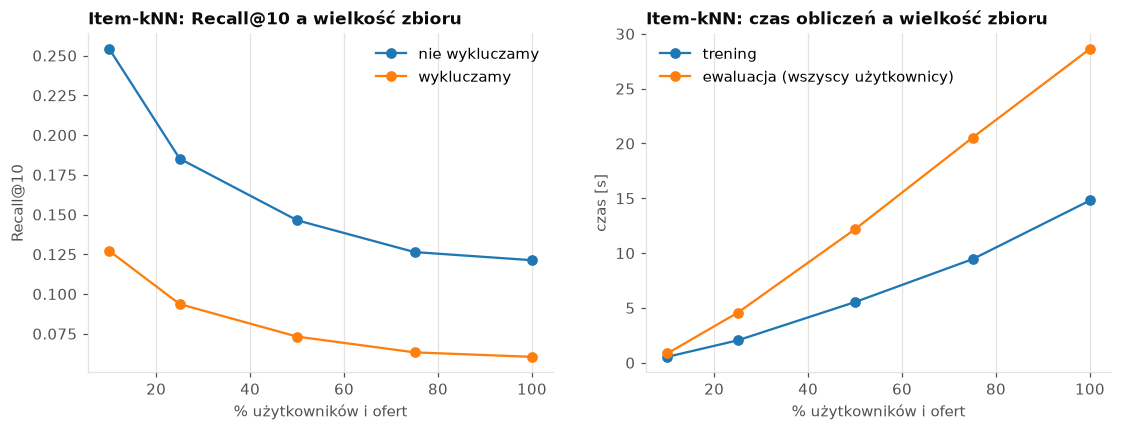

In [52]:
x = np.array(SCALES) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x, scale_results['Recall@10 (nie wykluczamy)'], marker='o', label='nie wykluczamy')
axes[0].plot(x, scale_results['Recall@10 (wykluczamy)'], marker='o', label='wykluczamy')
axes[0].set_title('Item-kNN: Recall@10 a wielkość zbioru')
axes[0].set_xlabel('% użytkowników i ofert')
axes[0].set_ylabel('Recall@10')
axes[0].legend()
axes[0].grid()

axes[1].plot(x, scale_results['czas treningu [s]'], marker='o', label='trening')
axes[1].plot(x, scale_results['czas ewaluacji [s]'], marker='o', label='ewaluacja (wszyscy użytkownicy)')
axes[1].set_title('Item-kNN: czas obliczeń a wielkość zbioru')
axes[1].set_xlabel('% użytkowników i ofert')
axes[1].set_ylabel('czas [s]')
axes[1].legend()
axes[1].grid()
plt.show()